![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Pipelines and Models

*Project 2 — Machine Learning: From Data to Predictions*

**Team:**
**Dataset:**

---

Steps 5 to 8 of the workflow: build the pipeline, compare models fairly, tune the best, and choose the threshold. Everything here uses the training set only.

> **Done when:** you have a comparison table of at least three model families on the same folds against the baseline, the best one or two tuned, and a final model chosen for reasons you can state.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import (
    cross_validate,
    GridSearchCV
)

from sklearn.metrics import mean_absolute_error

---
## 1. Load and split

The same loading and the same split as notebook 01. Put the code in `src/functions.py` so both notebooks use exactly the same rows.

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()

data_path = os.getenv("DATA_PATH")
if not data_path:
    raise ValueError("DATA_PATH is not set")

df = pd.read_excel(data_path)

from src.functions import prepare_unemployment_data

train, test, X_train, X_test, y_train, y_test = (
    prepare_unemployment_data(df)
)

print(X_train.shape)
print(X_test.shape)

(684, 6)
(142, 6)


In [3]:
cv_splits = []

for end_year in [2008, 2012, 2016]:

    train_idx = np.where(
        train["target_year"] <= end_year
    )[0]

    val_idx = np.where(
        (train["year"] >= end_year + 1) &
        (train["year"] <= end_year + 2)
    )[0]

    cv_splits.append((train_idx, val_idx))

We must use these same folds for all three models so the comparison is fair.

---
## 2. The preprocessing pipeline

A `ColumnTransformer` with one branch per column type: impute, scale, encode. **Everything that learns from data goes inside**, so cross-validation refits it on every fold.

In [4]:
numeric_features = X_train.columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features)
    ]
)

---
## 3. First model in the pipeline

One simple model at the end of the pipeline, scored with cross-validation. Is it better than the baseline, and by more than the spread across folds?

In [5]:
linear_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_scores = cross_validate(
    linear_pipeline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring="neg_mean_absolute_error"
)

linear_mae = -linear_scores["test_score"]

print("Linear Regression MAE:", linear_mae)
print("Average MAE:", linear_mae.mean())
print("Standard deviation:", linear_mae.std())

Linear Regression MAE: [0.92790151 0.72892129 0.61571821]
Average MAE: 0.7575136686609903
Standard deviation: 0.12904197413911062


---
## 4. Features

New features added inside the pipeline. Keep a feature only if it improves the cross-validated score, and write down what each one changed.

In [6]:
unemployment_only = Pipeline(steps=[
    ("preprocessor", ColumnTransformer([
        ("num", numeric_transformer, ["unemployment"])
    ])),
    ("model", LinearRegression())
])

only_scores = -cross_validate(
    unemployment_only,
    X_train,
    y_train,
    cv=cv_splits,
    scoring="neg_mean_absolute_error"
)["test_score"]

print("Unemployment only MAE:", only_scores.mean())
print("All six features MAE:", linear_mae.mean())

Unemployment only MAE: 0.9267831452968119
All six features MAE: 0.7575136686609903


---
## 5. Compare models

At least three model families on **the same folds**, with the mean and the spread. A table, and a chart of it.

In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = -cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring="neg_mean_absolute_error"
    )["test_score"]

    results.append({
        "Model": name,
        "MAE Mean": scores.mean(),
        "MAE Std": scores.std(),
        "Fold Scores": scores
    })

results_df = pd.DataFrame(results)

results_df.sort_values("MAE Mean")

,Model,MAE Mean,MAE Std,Fold Scores
1,Ridge,0.757132,0.130131,"[0.9304453972003779, 0.7240754251924907, 0.616..."
0,Linear Regression,0.757514,0.129042,"[0.9279015088748542, 0.7289212906268621, 0.615..."
2,Random Forest,1.047415,0.265774,"[1.3035306036356247, 1.15759479185853, 0.68111..."


In [8]:
baseline_results = pd.DataFrame([
    {
        "Model": "DummyRegressor",
        "MAE Mean": 3.364
    },
    {
        "Model": "Persistence",
        "MAE Mean": 0.848
    }
])

comparison_df = pd.concat(
    [
        results_df[["Model", "MAE Mean"]],
        baseline_results
    ],
    ignore_index=True
)

comparison_df.sort_values("MAE Mean")

,Model,MAE Mean
1,Ridge,0.757132
0,Linear Regression,0.757514
4,Persistence,0.848000
2,Random Forest,1.047415
3,DummyRegressor,3.364000


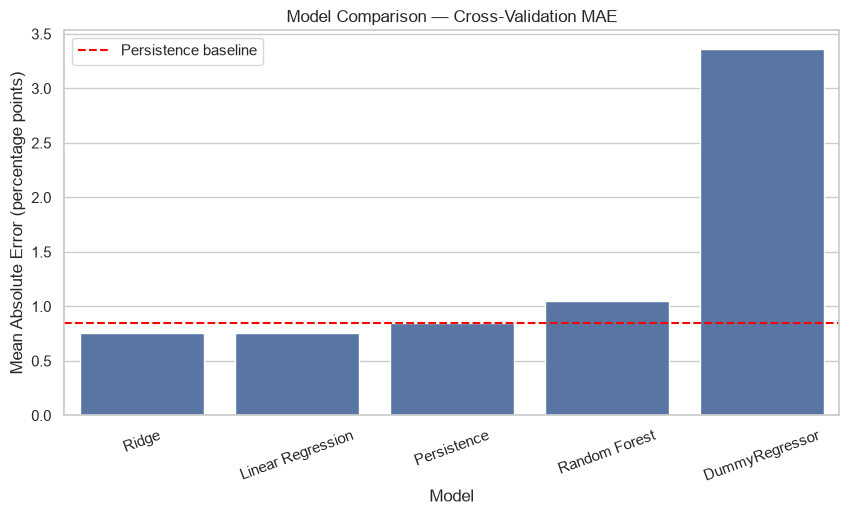

In [9]:
plot_df = comparison_df.sort_values("MAE Mean")

plt.figure(figsize=(10, 5))

sns.barplot(
    data=plot_df,
    x="Model",
    y="MAE Mean"
)

plt.axhline(
    y=0.848,
    color="red",
    linestyle="--",
    label="Persistence baseline"
)

plt.title("Model Comparison — Cross-Validation MAE")
plt.ylabel("Mean Absolute Error (percentage points)")
plt.xticks(rotation=20)
plt.legend()
plt.show()

---
## 6. Tune

A `GridSearchCV` or `RandomizedSearchCV` on the best one or two, on the training set. Report the best parameters and the cross-validated score.

In [10]:
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

ridge_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid=ridge_grid,
    cv=cv_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("Best parameters:", ridge_search.best_params_)
print("Best MAE:", -ridge_search.best_score_)

Best parameters: {'model__alpha': 1}
Best MAE: 0.7571316759510003


In [11]:
forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

forest_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5, 10],
    "model__min_samples_leaf": [2, 5]
}

forest_search = GridSearchCV(
    forest_pipeline,
    param_grid=forest_grid,
    cv=cv_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

forest_search.fit(X_train, y_train)

print("Best parameters:", forest_search.best_params_)
print("Best MAE:", -forest_search.best_score_)

Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Best MAE: 1.0072633842518617


In [12]:
tuned_results = pd.DataFrame({
    "Model": [
        "Ridge Tuned",
        "Random Forest Tuned"
    ],
    "MAE": [
        -ridge_search.best_score_,
        -forest_search.best_score_
    ]
})

tuned_results.sort_values("MAE")

,Model,MAE
0,Ridge Tuned,0.757132
1,Random Forest Tuned,1.007263


---
## 7. Threshold

Classification only. Cross-validated probabilities on the training set with `cross_val_predict`, then the threshold that fits your metric and the cost of each mistake. Regression: delete this section and say why in the README.



Threshold selection is not applicable to this project because the target variable, next-year unemployment, is continuous.

The models predict numerical unemployment rates rather than classification probabilities. Therefore, model performance is evaluated using Mean Absolute Error (MAE).

---
## 8. The final model

Which model, which parameters, which threshold, and why. If a simpler model is within the noise of the best one, say which you chose and why.

In [13]:
final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Tuned",
        "Random Forest Tuned",
        "Persistence Baseline"
    ],
    "MAE": [
        linear_mae.mean(),
        -ridge_search.best_score_,
        -forest_search.best_score_,
        0.848
    ]
})

final_comparison.sort_values("MAE")

,Model,MAE
1,Ridge Tuned,0.757132
0,Linear Regression,0.757514
3,Persistence Baseline,0.848000
2,Random Forest Tuned,1.007263


In [14]:
print("Best Ridge parameters:", ridge_search.best_params_)
print("Best Ridge MAE:", -ridge_search.best_score_)

Best Ridge parameters: {'model__alpha': 1}
Best Ridge MAE: 0.7571316759510003


In [15]:
ridge_cv = -cross_validate(
    ridge_search.best_estimator_,
    X_train,
    y_train,
    cv=cv_splits,
    scoring="neg_mean_absolute_error"
)["test_score"]

print("MAE per fold:", ridge_cv)
print("Mean MAE:", ridge_cv.mean())
print("Standard deviation:", ridge_cv.std())

MAE per fold: [0.9304454  0.72407543 0.61687421]
Mean MAE: 0.7571316759510003
Standard deviation: 0.13013136915698323


### Model Selection

Three regression model families were compared using chronological cross-validation and Mean Absolute Error (MAE).

Ridge Regression achieved the lowest average MAE (0.7571 percentage points), closely followed by Linear Regression (0.7575). Both improved upon the persistence baseline (0.8480) by approximately 10.7%.

The tuned Random Forest model performed worse (MAE = 1.0073), suggesting that greater model complexity did not improve predictive accuracy in this experiment.

Ridge Regression was selected provisionally because it achieved the lowest cross-validation error and includes regularization.

However, the difference between Ridge and Linear Regression was negligible, so there is not enough evidence to claim that Ridge is substantially more accurate.

The final selected pipeline will be fitted on the complete training dataset and evaluated on the untouched test period in Notebook 03.

Hyperparameter tuning resulted in only a small improvement in predictive performance. This suggests that model choice and feature selection had a greater impact than hyperparameter optimization.

---
## Image option

If you chose the flower photos, sections 2 to 7 become: rescaling and augmentation layers; a CNN from scratch trained with early stopping, with its training curves; a frozen pretrained network (for example `MobileNetV2`) with a new output layer, trained the same way; and the two compared on the validation set. Fine-tuning the top of the pretrained network is optional.

In [16]:
import joblib
from pathlib import Path

# Get the best Ridge pipeline from GridSearchCV
final_model = ridge_search.best_estimator_

# Train it on the complete training dataset
final_model.fit(X_train, y_train)

# Create the models folder if it doesn't exist
model_path = Path("../models/ridge_unemployment.pkl")
model_path.parent.mkdir(parents=True, exist_ok=True)

# Save the model
joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Location:", model_path.resolve())

Model saved successfully!
Location: C:\Users\rkham\Desktop\ironhack_project_ML\ML_project\models\ridge_unemployment.pkl
